# 11 — Final Model Comparison and Selection

**FYP:** Developing a Semi-Dynamic Landslide Susceptibility Decision-Support Dashboard Using Machine Learning for Malaysia

**Purpose:** Compare the same nested spatial-validation results from Stage 08 and Stage 09, incorporate Stage 10 robustness evidence, compare published benchmarks descriptively, and select provisional static and temporal algorithms before Stage 12 production training.

**Important:** This notebook does not fit a new production model or use the outer test folds for tuning. Final selection is a documented judgement, not proof of deployment readiness.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
warnings.filterwarnings("ignore", category=FutureWarning)

## 1. Project paths and file validation

In [2]:
PROJECT_ROOT = Path(r"C:\Landslide_FYP")

DEV_DIR = PROJECT_ROOT / "Landslide_FYP_Development"
RESULTS_DIR = DEV_DIR / "05_model_results"

STAGE08_DIR = RESULTS_DIR / "enhanced_static"
STAGE09_DIR = RESULTS_DIR / "temporal_incremental"
STAGE10_DIR = RESULTS_DIR / "stage10_robustness"
STAGE11_DIR = RESULTS_DIR / "stage11_final_model_selection"

STAGE11_DIR.mkdir(parents=True, exist_ok=True)

STAGE08_SUMMARY_PATH = STAGE08_DIR / "enhanced_model_summary.csv"
STAGE09_SUMMARY_PATH = STAGE09_DIR / "temporal_incremental_summary.csv"
STAGE10_SUMMARY_PATH = STAGE10_DIR / "stage10_robustness_summary.csv"
STAGE10_LIMITATIONS_PATH = STAGE10_DIR / "stage10_methodological_limitations.csv"
STAGE10_ABLATION_PATH = STAGE10_DIR / "temporal_ablation_summary.csv"
STAGE10_FOLD_PATH = STAGE10_DIR / "original_spatial_fold_stability.csv"

REQUIRED_PATHS = [
    STAGE08_SUMMARY_PATH,
    STAGE09_SUMMARY_PATH,
    STAGE10_SUMMARY_PATH,
    STAGE10_ABLATION_PATH,
]

missing_files = [str(path) for path in REQUIRED_PATHS if not path.exists()]

if missing_files:
    raise FileNotFoundError(
        "Missing required Stage 08/09/10 inputs:\n" + "\n".join(missing_files)
    )

print("All required input files found.")
print("Stage 11 outputs:", STAGE11_DIR)

All required input files found.
Stage 11 outputs: C:\Landslide_FYP\Landslide_FYP_Development\05_model_results\stage11_final_model_selection


# PART A — STANDARDIZE MODEL COMPARISON TABLES

## 2. Load the already validated nested spatial-CV summaries

**Important:** `roc_auc_mean` is the arithmetic mean of the five held-out fold ROC-AUC values, not the pooled OOF ROC-AUC. Compare models within the same branch/dataset only.

In [3]:
static_raw = pd.read_csv(STAGE08_SUMMARY_PATH)
temporal_raw = pd.read_csv(STAGE09_SUMMARY_PATH)
robustness = pd.read_csv(STAGE10_SUMMARY_PATH)
ablation = pd.read_csv(STAGE10_ABLATION_PATH)

ALGORITHMS = ["Logistic Regression", "Random Forest", "XGBoost"]

required_static = [
    "model", "roc_auc_mean", "roc_auc_std", "pr_auc_mean",
    "balanced_accuracy_mean", "recall_mean", "f1_mean", "roc_auc_gap_mean",
]
required_temporal = required_static + ["dataset", "variant"]

for table_name, frame, required in [
    ("Stage 08", static_raw, required_static),
    ("Stage 09", temporal_raw, required_temporal),
]:
    missing_cols = [c for c in required if c not in frame.columns]

    if missing_cols:
        raise ValueError(f"{table_name} missing columns: {missing_cols}")

static = static_raw[static_raw["model"].isin(ALGORITHMS)].copy()
temporal = temporal_raw.loc[
    temporal_raw["dataset"].eq("full_enhanced")
    & temporal_raw["variant"].eq("Static + temporal")
    & temporal_raw["model"].isin(ALGORITHMS)
].copy()

if set(static["model"]) != set(ALGORITHMS) or len(static) != 3:
    raise ValueError("Stage 08 must have one row for each algorithm.")

if set(temporal["model"]) != set(ALGORITHMS) or len(temporal) != 3:
    raise ValueError("Stage 09 full_enhanced must have one temporal row for each algorithm.")

print("STATIC COMPARISON (582 samples in the original benchmark)")
display(static[required_static].sort_values("roc_auc_mean", ascending=False))

print("TEMPORAL COMPARISON (363 matched samples in the original benchmark)")
display(temporal[required_static].sort_values("roc_auc_mean", ascending=False))

STATIC COMPARISON (582 samples in the original benchmark)


,model,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_accuracy_mean,recall_mean,f1_mean,roc_auc_gap_mean
0,Random Forest,0.905382,0.043344,0.806675,0.835204,0.822105,0.772014,0.076377
1,XGBoost,0.903359,0.038652,0.804187,0.829252,0.817895,0.765562,0.057486
2,Logistic Regression,0.875033,0.045517,0.725712,0.747011,0.749211,0.653613,0.061016


TEMPORAL COMPARISON (363 matched samples in the original benchmark)


,model,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_accuracy_mean,recall_mean,f1_mean,roc_auc_gap_mean
1,Random Forest,0.940446,0.032171,0.910528,0.844827,0.822101,0.781840,0.053686
2,XGBoost,0.933252,0.032219,0.899870,0.824366,0.831884,0.745236,0.056974
0,Logistic Regression,0.925323,0.056611,0.891471,0.835346,0.830072,0.770590,0.052222


## 3. Export complete fair-comparison tables

In [4]:
METRIC_COLUMNS = [
    "model", "accuracy_mean", "accuracy_std",
    "balanced_accuracy_mean", "balanced_accuracy_std",
    "precision_mean", "precision_std", "recall_mean", "recall_std",
    "f1_mean", "f1_std", "roc_auc_mean", "roc_auc_std",
    "pr_auc_mean", "pr_auc_std", "roc_auc_gap_mean",
]

static_comparison = static[
    [c for c in METRIC_COLUMNS if c in static.columns]
].sort_values("roc_auc_mean", ascending=False).reset_index(drop=True)

temporal_comparison = temporal[
    [c for c in METRIC_COLUMNS if c in temporal.columns]
].sort_values("roc_auc_mean", ascending=False).reset_index(drop=True)

static_comparison.to_csv(STAGE11_DIR / "static_algorithm_comparison.csv", index=False)
temporal_comparison.to_csv(STAGE11_DIR / "temporal_algorithm_comparison.csv", index=False)

print("Exported static and temporal comparison tables.")

Exported static and temporal comparison tables.


# PART B — DESCRIPTIVE MODEL-SELECTION CRITERIA

## 4. Apply transparent suitability checks

The rules below are *screening heuristics* used to support a documented recommendation; they are not statistically validated pass/fail thresholds. Main criterion is held-out spatial ROC-AUC, with PR-AUC, balanced accuracy, recall, stability and training–testing gap as supporting evidence. Differences of only a few thousandths do **not** establish statistical superiority.

In [5]:
def build_selection_audit(table, branch):
    result = table.copy()

    result["branch"] = branch
    result["roc_auc_rank"] = result["roc_auc_mean"].rank(
        ascending=False, method="min"
    ).astype(int)
    result["pr_auc_rank"] = result["pr_auc_mean"].rank(
        ascending=False, method="min"
    ).astype(int)
    result["balanced_accuracy_rank"] = result["balanced_accuracy_mean"].rank(
        ascending=False, method="min"
    ).astype(int)
    result["recall_rank"] = result["recall_mean"].rank(
        ascending=False, method="min"
    ).astype(int)

    result["roc_auc_minus_1std"] = (
        result["roc_auc_mean"] - result["roc_auc_std"]
    )
    result["within_0_02_best_auc"] = (
        result["roc_auc_mean"] >= result["roc_auc_mean"].max() - 0.02
    )
    result["gap_over_0_10"] = result["roc_auc_gap_mean"] > 0.10

    return result.sort_values(
        ["roc_auc_rank", "pr_auc_rank", "balanced_accuracy_rank"]
    ).reset_index(drop=True)

static_audit = build_selection_audit(static_comparison, "static")
temporal_audit = build_selection_audit(temporal_comparison, "temporal")

static_audit.to_csv(STAGE11_DIR / "static_selection_audit.csv", index=False)
temporal_audit.to_csv(STAGE11_DIR / "temporal_selection_audit.csv", index=False)

display(static_audit[[
    "model", "roc_auc_mean", "roc_auc_std", "pr_auc_mean",
    "balanced_accuracy_mean", "recall_mean", "roc_auc_gap_mean",
    "within_0_02_best_auc", "gap_over_0_10",
]])

display(temporal_audit[[
    "model", "roc_auc_mean", "roc_auc_std", "pr_auc_mean",
    "balanced_accuracy_mean", "recall_mean", "roc_auc_gap_mean",
    "within_0_02_best_auc", "gap_over_0_10",
]])

,model,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_accuracy_mean,recall_mean,roc_auc_gap_mean,within_0_02_best_auc,gap_over_0_10
0,Random Forest,0.905382,0.043344,0.806675,0.835204,0.822105,0.076377,True,False
1,XGBoost,0.903359,0.038652,0.804187,0.829252,0.817895,0.057486,True,False
2,Logistic Regression,0.875033,0.045517,0.725712,0.747011,0.749211,0.061016,False,False


,model,roc_auc_mean,roc_auc_std,pr_auc_mean,balanced_accuracy_mean,recall_mean,roc_auc_gap_mean,within_0_02_best_auc,gap_over_0_10
0,Random Forest,0.940446,0.032171,0.910528,0.844827,0.822101,0.053686,True,False
1,XGBoost,0.933252,0.032219,0.899870,0.824366,0.831884,0.056974,True,False
2,Logistic Regression,0.925323,0.056611,0.891471,0.835346,0.830072,0.052222,True,False


## 5. Plot ROC-AUC means and fold standard deviations

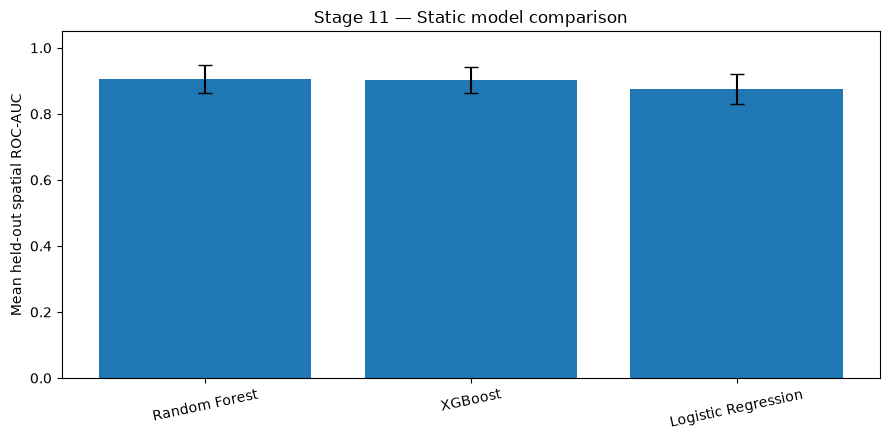

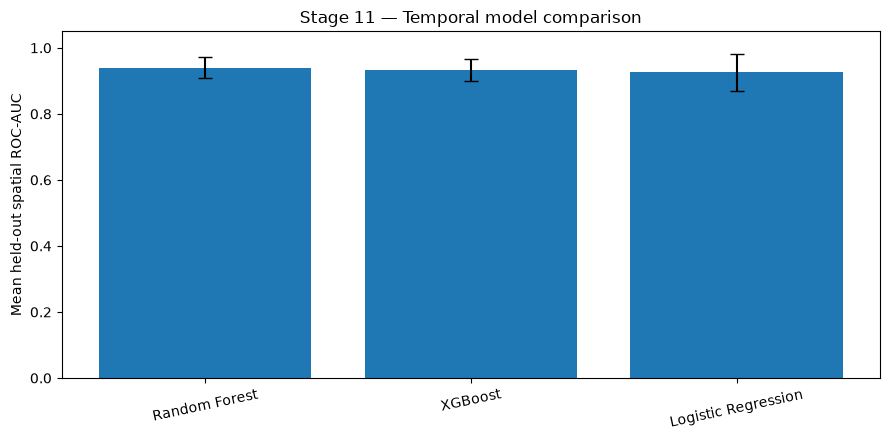

In [6]:
for branch, table in [
    ("static", static_comparison),
    ("temporal", temporal_comparison),
]:
    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.bar(
        table["model"],
        table["roc_auc_mean"],
        yerr=table["roc_auc_std"],
        capsize=5,
    )

    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Mean held-out spatial ROC-AUC")
    ax.set_title(f"Stage 11 — {branch.title()} model comparison")
    ax.tick_params(axis="x", rotation=12)
    fig.tight_layout()
    fig.savefig(STAGE11_DIR / f"{branch}_roc_auc_comparison.png", dpi=180)
    plt.show()
    plt.close(fig)

# PART C — STAGE 10 ROBUSTNESS AND TEMPORAL ABLATION

## 6. Extract pre-existing robustness observations

The Stage 10 fixed-RF tests supplement the nested Stage 08/09 model benchmarks; they are **not** a fourth fair algorithm comparison.

In [7]:
robustness_subset = robustness.loc[
    robustness["test_family"].isin([
        "Primary static RF", "Pseudo-absence ratio",
        "Repeated spatial partitions", "Spatial block size",
        "Temporal feature ablation",
    ])
].copy()

robustness_subset.to_csv(
    STAGE11_DIR / "stage10_robustness_evidence.csv", index=False
)

ablation.to_csv(STAGE11_DIR / "stage10_temporal_ablation_evidence.csv", index=False)

display(robustness_subset[[
    "test_family", "experiment", "mean_roc_auc", "std_roc_auc",
    "mean_train_test_auc_gap",
]])

display(ablation.sort_values("mean_roc_auc", ascending=False))

if STAGE10_LIMITATIONS_PATH.exists():
    limitations = pd.read_csv(STAGE10_LIMITATIONS_PATH)
else:
    limitations = pd.DataFrame({
        "issue": ["Stage 10 limitations file missing"],
        "status": ["Manually review the stage10_methodological_limitations.csv file."],
    })

limitations.to_csv(STAGE11_DIR / "methodological_limitations.csv", index=False)
display(limitations)

,test_family,experiment,mean_roc_auc,std_roc_auc,mean_train_test_auc_gap
0,Primary static RF,static_primary_fixed_rf,0.904600,0.046981,0.083358
1,Pseudo-absence ratio,static_primary_fixed_rf,0.904600,0.046981,0.083358
2,Pseudo-absence ratio,static_ratio_1to1,0.869263,0.046466,0.116176
3,Repeated spatial partitions,repeat_1,0.904600,0.046981,0.083358
4,Repeated spatial partitions,repeat_2,0.907110,0.047208,0.081006
5,Repeated spatial partitions,repeat_3,0.909421,0.037829,0.078587
6,Spatial block size,block_0.225_deg,0.890739,0.034942,0.097609
7,Spatial block size,block_0.450_deg,0.904600,0.046981,0.083358
8,Spatial block size,block_0.675_deg,0.853917,0.066127,0.135150
9,Temporal feature ablation,full_temporal,0.934265,0.035926,0.059438


,experiment,mean_roc_auc,std_roc_auc,mean_pr_auc,mean_balanced_accuracy,mean_gap_roc_auc
4,without_soil_moisture,0.935467,0.030368,0.908890,0.869122,0.057361
3,without_rainfall,0.934914,0.032573,0.907623,0.857740,0.057042
0,full_temporal,0.934265,0.035926,0.905102,0.843669,0.059438
2,without_landcover,0.904684,0.055197,0.830421,0.829881,0.088409
5,without_waterway,0.903776,0.062759,0.863734,0.826137,0.088778
1,static_only,0.837086,0.093806,0.700239,0.696588,0.144127


,issue,status
0,Pseudo-absence uncertainty,Not resolved by 1:1 vs 1:2 comparison; separat...
1,Spatial buffer,Spatial block groups applied; no explicit excl...
2,Temporal causality,Verify event/control reference dates and data ...
3,National raster coverage,Not proven; validate completeness of all natio...
4,Susceptibility score calibration,Case-control scores are relative; do not inter...
5,Hyperparameter tuning,Stage 10 uses fixed RF settings; final compari...


# PART D — PUBLISHED STUDY COMPARISON

## 7. Literature benchmarks supplied in the FYP research summary

These values come from your study notes; confirm the original journal articles, exact metric definitions and citations before including them in the final report. They are NOT direct performance targets.

In [8]:
literature = pd.DataFrame([
    {"study": "Wang et al. (2024)", "model": "Random Forest", "roc_auc": 0.904},
    {"study": "Zhang et al. (2024)", "model": "Logistic Regression", "roc_auc": 0.752},
    {"study": "Zhang et al. (2024)", "model": "Random Forest", "roc_auc": 0.965},
    {"study": "Zhang et al. (2024)", "model": "XGBoost", "roc_auc": 0.998},
    {"study": "Halder et al. (2025)", "model": "Logistic Regression", "roc_auc": 0.935},
    {"study": "Halder et al. (2025)", "model": "Random Forest", "roc_auc": 0.983},
    {"study": "Halder et al. (2025)", "model": "XGBoost", "roc_auc": 0.987},
])

ours_static = static_comparison[["model", "roc_auc_mean"]].copy()
ours_static["study"] = "This FYP — static nested spatial CV"
ours_static = ours_static.rename(columns={"roc_auc_mean": "roc_auc"})

ours_temporal = temporal_comparison[["model", "roc_auc_mean"]].copy()
ours_temporal["study"] = "This FYP — temporal nested spatial CV"
ours_temporal = ours_temporal.rename(columns={"roc_auc_mean": "roc_auc"})

literature_comparison = pd.concat([
    literature,
    ours_static[["study", "model", "roc_auc"]],
    ours_temporal[["study", "model", "roc_auc"]],
], ignore_index=True)

literature_comparison["comparability_note"] = (
    "Descriptive only; datasets, sampling and validation are different"
)

literature_comparison.to_csv(
    STAGE11_DIR / "descriptive_literature_comparison.csv", index=False
)

display(literature_comparison)

,study,model,roc_auc,comparability_note
0,Wang et al. (2024),Random Forest,0.904000,"Descriptive only; datasets, sampling and valid..."
1,Zhang et al. (2024),Logistic Regression,0.752000,"Descriptive only; datasets, sampling and valid..."
2,Zhang et al. (2024),Random Forest,0.965000,"Descriptive only; datasets, sampling and valid..."
3,Zhang et al. (2024),XGBoost,0.998000,"Descriptive only; datasets, sampling and valid..."
4,Halder et al. (2025),Logistic Regression,0.935000,"Descriptive only; datasets, sampling and valid..."
5,Halder et al. (2025),Random Forest,0.983000,"Descriptive only; datasets, sampling and valid..."
6,Halder et al. (2025),XGBoost,0.987000,"Descriptive only; datasets, sampling and valid..."
7,This FYP — static nested spatial CV,Random Forest,0.905382,"Descriptive only; datasets, sampling and valid..."
8,This FYP — static nested spatial CV,XGBoost,0.903359,"Descriptive only; datasets, sampling and valid..."
9,This FYP — static nested spatial CV,Logistic Regression,0.875033,"Descriptive only; datasets, sampling and valid..."


# PART E — FINAL PROVISIONAL SELECTION RECORD

## 8. Identify evidence-supported candidates

These candidates use the top nested spatial ROC-AUC within **each separate branch**. Do not compare the static and temporal branches to select one national model. The final model choice remains subject to the mapped-feature coverage and leakage checks below.

In [9]:
static_candidate = static_audit.iloc[0]["model"]
temporal_candidate = temporal_audit.iloc[0]["model"]

selection = pd.DataFrame([
    {
        "branch": "Static Malaysia-wide susceptibility",
        "recommended_algorithm": static_candidate,
        "selection_status": "Provisional — proceed to production-readiness checks",
        "validation_basis": "Stage 08 nested 5-fold outer / 3-fold inner spatial CV",
        "eligible_samples": 582,
        "primary_metric": "mean spatial ROC-AUC",
        "deployment_condition": "Confirm nationally available predictors, valid rasters and leakage controls",
    },
    {
        "branch": "Semi-dynamic environmental-condition extension",
        "recommended_algorithm": temporal_candidate,
        "selection_status": "Provisional — time-index and coverage review required",
        "validation_basis": "Stage 09 matched full-enhanced nested spatial CV",
        "eligible_samples": 363,
        "primary_metric": "mean spatial ROC-AUC",
        "deployment_condition": "Confirm historical date cutoffs, temporal coverage and no future leakage",
    },
])

selection.to_csv(STAGE11_DIR / "provisional_model_selection.csv", index=False)

print("Provisional static candidate:", static_candidate)
print("Provisional temporal candidate:", temporal_candidate)
display(selection)

Provisional static candidate: Random Forest
Provisional temporal candidate: Random Forest


,branch,recommended_algorithm,selection_status,validation_basis,eligible_samples,primary_metric,deployment_condition
0,Static Malaysia-wide susceptibility,Random Forest,Provisional — proceed to production-readiness ...,Stage 08 nested 5-fold outer / 3-fold inner sp...,582,mean spatial ROC-AUC,"Confirm nationally available predictors, valid..."
1,Semi-dynamic environmental-condition extension,Random Forest,Provisional — time-index and coverage review r...,Stage 09 matched full-enhanced nested spatial CV,363,mean spatial ROC-AUC,"Confirm historical date cutoffs, temporal cove..."


## 9. Record issues to resolve before Stage 12 production fitting

Check these in your local datasets and explain outstanding limitations in your report. A passing notebook does **not** establish that the entire national raster can be predicted.

In [10]:
readiness = pd.DataFrame([
    {
        "check": "Predictor availability over all Malaysia",
        "required_action": "Audit raster coverage and masks for every selected static predictor",
        "status": "Pending geographic raster audit",
    },
    {
        "check": "Case-control prevalence and score interpretation",
        "required_action": "Label RF outputs as relative scores, not national occurrence probability",
        "status": "Required at deployment",
    },
    {
        "check": "Independent pseudo-absence redraw",
        "required_action": "Run if feasible, or disclose untested sensitivity",
        "status": "Not completed by Stage 10",
    },
    {
        "check": "Spatial leakage buffer",
        "required_action": "Inspect positive/control grouping and consider buffered spatial CV",
        "status": "Not completed by Stage 10",
    },
    {
        "check": "Historical timestamps and temporal inputs",
        "required_action": "Verify each case/control reference date and available predictors strictly precede it",
        "status": "Pending audit",
    },
    {
        "check": "Five susceptibility class thresholds",
        "required_action": "Set and document thresholds after national predictions are assessed",
        "status": "Stage 13/14; not selected here",
    },
])

readiness.to_csv(STAGE11_DIR / "stage12_readiness_checklist.csv", index=False)
display(readiness)

print("Stage 11 complete — review the provisional selection and readiness checklist.")
print("No production model was trained in this notebook.")

,check,required_action,status
0,Predictor availability over all Malaysia,Audit raster coverage and masks for every sele...,Pending geographic raster audit
1,Case-control prevalence and score interpretation,"Label RF outputs as relative scores, not natio...",Required at deployment
2,Independent pseudo-absence redraw,"Run if feasible, or disclose untested sensitivity",Not completed by Stage 10
3,Spatial leakage buffer,Inspect positive/control grouping and consider...,Not completed by Stage 10
4,Historical timestamps and temporal inputs,Verify each case/control reference date and av...,Pending audit
5,Five susceptibility class thresholds,Set and document thresholds after national pre...,Stage 13/14; not selected here


Stage 11 complete — review the provisional selection and readiness checklist.
No production model was trained in this notebook.


## 10. Next stage

**Stage 12 — Production model training:** Reproduce the selected Stage 08/09 model pipelines and tuned hyperparameters, fit each final pipeline on its entire eligible development dataset, then serialize the pipeline with feature names, categorical mappings, package versions and model metadata. Do not call full-data training metrics independent validation.

**Stage 13 — Malaysia-wide mapping:** Before building a raster surface, audit the national extent and missing-data masks of every feature used by the static model.